# 02 — التدريب: Siamese U-Net لاكتشاف التغيّر

- **المعمارية:** encoder مشترك الأوزان (Siamese) يعالج الصورتين، ثم دمج
  بالتسلسل (concatenation) عند كل مستوى، وdecoder بنمط U-Net يخرج logits
  لقناع التغيّر.
- **الخسارة:** `BCEWithLogitsLoss + Dice` (مناسبة لعدم توازن ~5% بكسل متغير).
- **Augmentation متزامن:** قصّة عشوائية 256×256 + انعكاس أفقي/رأسي + دوران
  k×90° بنفس المعاملات على (A, B, mask) — لا يكسر التطابق المكاني.
- **المقاييس لكل epoch:** loss / Precision / Recall / F1 / IoU على train وval،
  مع early stopping وحفظ أفضل checkpoint حسب val IoU.

> التدريب الكامل (~40 epoch) يستغرق ≈ 1.5–2 ساعة على RTX 3050. لتنفيذ كامل
> غير تفاعلي استخدم `python train.py`. هذا الدفتر ينفّذ نفس الحلقة تفاعليًا،
> ويمكنك مقاطعته (interrupt) دون فقدان أفضل checkpoint لأنه يُحفظ في كل تحسن.

**تنبيه مهم:** العداد `ConfusionMeter` يطبّق sigmoid داخليًا — يجب تمرير
**logits خام** وليس احتمالات (تمرير probs يسبب double-sigmoid ويفسد المقاييس؛
خطأ اكتُشف وأُصلح في هذا المشروع).

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():   # kernel cwd may be notebooks/
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

import random, time

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader

from src import config
from src.data_discovery import build_samples, download_dataset
from src.dataset import EvalTileDataset, TrainChangeDataset, samples_for_split
from src.losses import BCEDiceLoss
from src.metrics import ConfusionMeter
from src.model import SiameseUNet, count_parameters

SEED = config.SEED
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"
print("device:", device, "| AMP:", USE_AMP)

device: cuda | AMP: True


In [2]:
root = download_dataset()
samples, notes = build_samples(root)
train_s = samples_for_split(samples, "train")
val_s = samples_for_split(samples, "val")
print(f"train={len(train_s)}  val={len(val_s)}")
for n in notes:
    print("  note:", n)

train_ds = TrainChangeDataset(train_s, image_size=config.IMAGE_SIZE, augment=True)
val_ds = EvalTileDataset(val_s, image_size=config.IMAGE_SIZE)  # tiles حتمية للـvalidation
train_dl = DataLoader(train_ds, batch_size=config.BATCH_SIZE, shuffle=True,
                      num_workers=config.NUM_WORKERS, pin_memory=True, drop_last=True)
val_dl = DataLoader(val_ds, batch_size=config.BATCH_SIZE, shuffle=False,
                    num_workers=config.NUM_WORKERS, pin_memory=False)
print(f"train steps/epoch: {len(train_dl)}  |  val tiles: {len(val_ds)}")

[data] Downloading / locating dataset 'mdrifaturrahman33/levir-cd-change-detection' ...
[data] kagglehub cache: D:\DEPI Project\.kagglehub_cache


[data] Dataset root: D:\DEPI Project\.kagglehub_cache\datasets\mdrifaturrahman33\levir-cd-change-detection\versions\1

[data] Detected role folders:
    [   A] D:\DEPI Project\.kagglehub_cache\datasets\mdrifaturrahman33\levir-cd-change-detection\versions\1\LEVIR-CD+\test\A
    [   B] D:\DEPI Project\.kagglehub_cache\datasets\mdrifaturrahman33\levir-cd-change-detection\versions\1\LEVIR-CD+\test\B
    [mask] D:\DEPI Project\.kagglehub_cache\datasets\mdrifaturrahman33\levir-cd-change-detection\versions\1\LEVIR-CD+\test\label
    [   A] D:\DEPI Project\.kagglehub_cache\datasets\mdrifaturrahman33\levir-cd-change-detection\versions\1\LEVIR-CD+\train\A
    [   B] D:\DEPI Project\.kagglehub_cache\datasets\mdrifaturrahman33\levir-cd-change-detection\versions\1\LEVIR-CD+\train\B
    [mask] D:\DEPI Project\.kagglehub_cache\datasets\mdrifaturrahman33\levir-cd-change-detection\versions\1\LEVIR-CD+\train\label
train=689  val=147
  note: Official splits absent or incomplete -- all samples will be poo

train steps/epoch: 43  |  val tiles: 2352


In [3]:
model = SiameseUNet(in_ch=config.IN_CHANNELS, base=config.BASE_CHANNELS).to(device)
print(f"parameters: {count_parameters(model)/1e6:.2f} M")

criterion = BCEDiceLoss(config.BCE_WEIGHT, config.DICE_WEIGHT).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=config.LEARNING_RATE,
                              weight_decay=config.WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=config.LR_SCHEDULER_FACTOR,
    patience=config.LR_SCHEDULER_PATIENCE)
scaler = torch.amp.GradScaler(enabled=USE_AMP)

run_dir = config.OUTPUT_DIR / f"run_nb_{time.strftime('%Y%m%d_%H%M%S')}"
run_dir.mkdir(parents=True, exist_ok=True)
print("run dir:", run_dir)

parameters: 9.07 M


run dir: D:\DEPI Project\outputs\run_nb_20261012_122117


In [4]:
def run_epoch(model, loader, criterion, optimizer, scaler, device, threshold=0.5):
    model.train()
    meter, losses = ConfusionMeter(), []
    for batch in loader:
        a = batch["a"].to(device, non_blocking=True)
        b = batch["b"].to(device, non_blocking=True)
        y = batch["mask"].to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        if USE_AMP:
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                logits = model(a, b)
                loss = criterion(logits, y)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), config.GRAD_CLIP)
            scaler.step(optimizer); scaler.update()
        else:
            logits = model(a, b)
            loss = criterion(logits, y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), config.GRAD_CLIP)
            optimizer.step()
        losses.append(loss.item())
        meter.update(logits.float(), y, threshold)   # <-- logits خام
    return float(np.mean(losses)), meter.metrics()


@torch.no_grad()
def eval_epoch(model, loader, criterion, device, threshold=0.5):
    model.eval()
    meter, losses = ConfusionMeter(), []
    for batch in loader:
        a = batch["a"].to(device, non_blocking=True)
        b = batch["b"].to(device, non_blocking=True)
        y = batch["mask"].to(device, non_blocking=True)
        if USE_AMP:
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                logits = model(a, b); loss = criterion(logits, y)
        else:
            logits = model(a, b); loss = criterion(logits, y)
        losses.append(loss.item())
        metas = batch["meta"]
        for j in range(logits.shape[0]):   # استبعاد الـpadding من المقاييس
            vh, vw = int(metas["valid_h"][j]), int(metas["valid_w"][j])
            meter.update(logits.float()[j, :, :vh, :vw], y[j, :, :vh, :vw], threshold)
    return float(np.mean(losses)), meter.metrics()
print("epoch functions ready")

epoch functions ready


## حلقة التدريب

اضبط `EPOCHS` (الافتراضي هنا 5 كتجربة سريعة؛ التدريب الكامل 40 عبر `train.py`
أو ضع 40 هنا واستعد للانتظار). الـcheckpoint الأفضل يُحفظ تلقائيًا عند كل تحسن.

In [5]:
EPOCHS = 5            # quick demo; full training: python train.py or EPOCHS = 40
history, best_iou, best_epoch = [], -1.0, -1

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_m = run_epoch(model, train_dl, criterion, optimizer, scaler, device)
    va_loss, va_m = eval_epoch(model, val_dl, criterion, device)
    scheduler.step(va_m["iou"])
    history.append({"epoch": epoch, "train_loss": tr_loss, "val_loss": va_loss,
                    "train_iou": tr_m["iou"], "val_iou": va_m["iou"],
                    "val_f1": va_m["f1"], "lr": optimizer.param_groups[0]["lr"]})
    star = ""
    if va_m["iou"] > best_iou:
        best_iou, best_epoch = va_m["iou"], epoch
        torch.save({"model": model.state_dict(), "epoch": epoch,
                    "val_iou": va_m["iou"], "val_f1": va_m["f1"]},
                   run_dir / "best_model.pt")
        star = "  *best*"
    print(f"ep {epoch:3d} | train {tr_loss:.4f} IoU {tr_m['iou']:.3f} | "
          f"val {va_loss:.4f} IoU {va_m['iou']:.3f} F1 {va_m['f1']:.3f} "
          f"({time.time()-t0:.0f}s){star}")
print(f"\nbest epoch {best_epoch} | best val IoU {best_iou:.4f}")
print("checkpoint:", run_dir / "best_model.pt")

ep   1 | train 0.7250 IoU 0.072 | val 1.6123 IoU 0.072 F1 0.135 (54s)  *best*


ep   2 | train 0.6313 IoU 0.163 | val 0.6273 IoU 0.228 F1 0.372 (51s)  *best*


ep   3 | train 0.5847 IoU 0.211 | val 0.5760 IoU 0.239 F1 0.386 (52s)  *best*


ep   4 | train 0.5486 IoU 0.284 | val 0.5708 IoU 0.218 F1 0.358 (52s)


ep   5 | train 0.5320 IoU 0.282 | val 0.5303 IoU 0.238 F1 0.385 (52s)

best epoch 3 | best val IoU 0.2394
checkpoint: D:\DEPI Project\outputs\run_nb_20261012_122117\best_model.pt


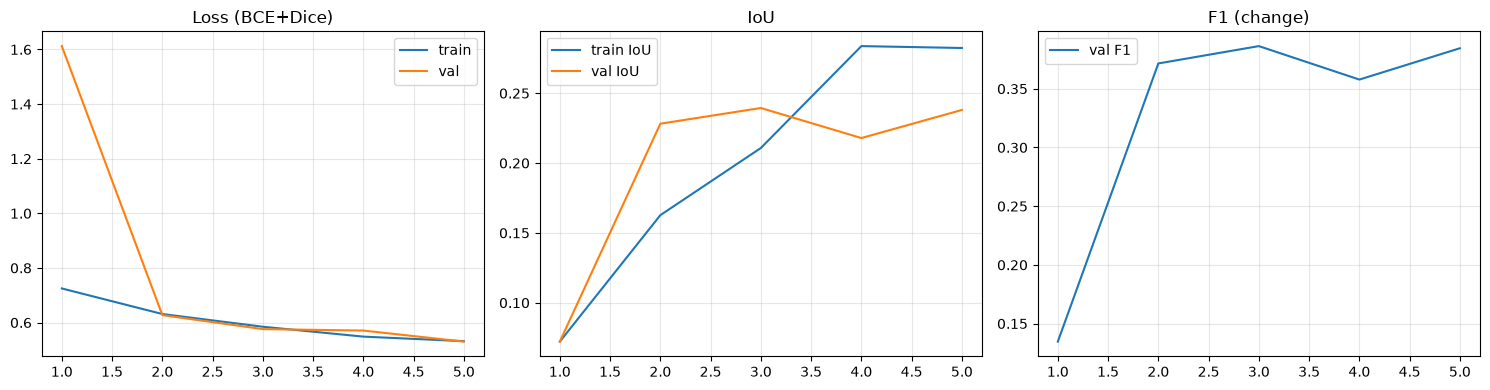

In [6]:
ep = [h["epoch"] for h in history]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(ep, [h["train_loss"] for h in history], label="train")
ax[0].plot(ep, [h["val_loss"] for h in history], label="val")
ax[0].set_title("Loss (BCE+Dice)"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(ep, [h["train_iou"] for h in history], label="train IoU")
ax[1].plot(ep, [h["val_iou"] for h in history], label="val IoU")
ax[1].set_title("IoU"); ax[1].legend(); ax[1].grid(alpha=0.3)
ax[2].plot(ep, [h["val_f1"] for h in history], label="val F1")
ax[2].set_title("F1 (change)"); ax[2].legend(); ax[2].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(run_dir / "curves.png", dpi=110)
plt.show()